# What changed in the room, walked through

Two phone videos of the same room, taken at different times. What moved, what
appeared, what is gone.

The full pipeline needs COLMAP, a depth model and about a gigabyte of weights,
so running it here would not be sensible. What this notebook does instead is
show the idea the whole project rests on, using the real functions on small
arrays you can read, and then load the saved output of a real run and mark it
against an answer that was known in advance.

**Where the numbers come from**

| Step | File | Produces |
|---|---|---|
| 1. Test scene | `tools/make_synthetic_room.py` | two videos, with the changes scripted |
| 2. Pipeline | `run.py` | `output/changes.json`, `report.md`, `scene.html` |
| 3. Committed run | `examples/changes.json` | the output this notebook reads |
| 4. Charts | `tools/make_readme_figures.py` | `docs/figures/*.png`, from that file only |

Nothing here is typed in by hand.

In [1]:
import sys, os, json, re
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
from src.occupancy import pack, unpack

print('numpy', np.__version__)

numpy 2.2.6


## 1. Why comparing two point clouds does not work

Point two cameras at the same room on different days and almost everything looks
different. You stood somewhere else, you held the phone at a different angle,
you walked a different route, things got hidden behind other things.

Here is the problem in miniature. Three places in a room, and what each visit
saw.

- **A chair** that was there on the first visit and genuinely taken away
- **A shelf** that was there both times and never moved
- **A corner** that only the first visit looked at, because the second walk
  missed it

The naive test is *occupied before, not occupied now*. Watch what it does.

In [2]:
# voxel coordinates, as (x, y, z) integers on the grid
chair  = np.array([[10, 2, 30]])
shelf  = np.array([[20, 4, 30]])
corner = np.array([[40, 2, 60]])

# visit A looked at all three and found something at each
a_occupied = pack(np.vstack([chair, shelf, corner]))

# visit B saw the shelf, saw through where the chair was, never looked at the corner
b_occupied = pack(shelf)
b_free     = pack(chair)          # a ray passed through and hit something further away

naive = np.setdiff1d(a_occupied, b_occupied)
print('naive: occupied in A and not occupied in B')
for key in naive:
    print('   ', unpack(np.array([key]))[0])

naive: occupied in A and not occupied in B
    [10  2 30]
    [40  2 60]


The naive test reports **two** things gone. One of them is right. The other is
the corner, which nobody looked at on the second visit. The chair and the corner
are indistinguishable to it, because an absence of evidence looks exactly like
evidence of absence.

On real footage, where nobody walks the identical route twice, that second
category is most of the room.

## 2. Tracking empty space is what fixes it

Each visit records three states, not one.

| | |
|---|---|
| **occupied** | depth measurements landed here |
| **free** | a camera ray passed through here on its way to a surface further away, so this space was looked at and there was nothing in it |
| **unknown** | neither, so nothing can be said |

Then change becomes an intersection rather than a subtraction. This is the exact
operation `src/changes.py` performs.

In [3]:
removed = np.intersect1d(a_occupied, b_free, assume_unique=True)

print('with free space: occupied in A AND positively free in B')
for key in removed:
    print('   ', unpack(np.array([key]))[0], ' <- the chair, correctly')
print()
print('the corner is not reported, because nothing was ever observed there.')
print('it is unknown, not empty, and the difference matters.')

with free space: occupied in A AND positively free in B
    [10  2 30]  <- the chair, correctly

the corner is not reported, because nothing was ever observed there.
it is unknown, not empty, and the difference matters.


One line of set algebra, and the false positive disappears.

This is the whole argument of the project. It makes the system **conservative**:
it will miss real changes in parts of the room only one visit covered. For
anything a robot navigates with, that is the right way to fail. Saying "the
doorway is clear" because nobody looked at it is far worse than saying nothing.

## 3. A practical detail worth seeing

A room at five centimetre resolution is tens of millions of voxels, and the
comparison above has to run over all of them. Holding them as `(x, y, z)` triples
and comparing rows would be slow.

Instead each voxel coordinate is packed into a single 64 bit integer, 21 bits per
axis. Set operations then run on flat integer arrays, which numpy does very
fast.

In [4]:
coords = np.array([[10, 2, 30], [-5, 0, 7], [40, 2, 60]])
keys = pack(coords)

for c, k in zip(coords, keys):
    print('%-16s -> %-22d -> %s' % (c, k, unpack(np.array([k]))[0]))

print()
print('round trip is exact:', np.array_equal(unpack(keys), coords))
print('dtype:', keys.dtype, ' so numpy set operations work directly on them')

[10  2 30]       -> 4611732197920997406    -> [10  2 30]
[-5  0  7]       -> 4611666227219136519    -> [-5  0  7]
[40  2 60]       -> 4611864139316330556    -> [40  2 60]

round trip is exact: True
dtype: int64  so numpy set operations work directly on them


Negative coordinates work because the pack shifts by an offset first. The round
trip is lossless, which the tests check.

## 4. The real run

`tools/make_synthetic_room.py` renders two videos of an imaginary room. Between
them one object moves across the room, one is taken away, one is added, and one
stays exactly where it was. Because the changes are scripted, the output can be
marked rather than admired.

`examples/changes.json` is the committed output of that run.

In [5]:
with open('../examples/changes.json') as f:
    changes = json.load(f)

print('%d changes reported\n' % len(changes))
print('%-9s %8s  %-22s %s' % ('kind', 'volume', 'centroid (x, y, z)', 'label'))
print('-' * 72)
for c in changes:
    print('%-9s %7.3f m3  (%6.2f,%6.2f,%6.2f)  %s'
          % (c['kind'], c['volume_m3'], *c['centroid'], c['label']))

10 changes reported

kind        volume  centroid (x, y, z)     label
------------------------------------------------------------------------
removed     0.284 m3  ( -0.31,  0.64,  3.30)  unidentified object
removed     0.264 m3  (  1.49,  0.22,  1.90)  unidentified object
removed     0.167 m3  ( -0.46, -0.05,  2.04)  unidentified object
removed     0.064 m3  ( -1.27,  0.57,  2.09)  unidentified object
removed     0.014 m3  ( -0.26,  1.37,  2.46)  unlabelled
removed     0.010 m3  (  2.01,  0.27,  3.40)  unidentified object
added       0.375 m3  (  0.72,  0.07,  2.54)  unidentified object
added       0.188 m3  ( -1.09,  0.39,  1.95)  unidentified object
added       0.088 m3  (  1.65,  0.79,  3.19)  unidentified object
added       0.036 m3  ( -0.97,  0.31,  3.60)  unidentified object


## 5. Marking it

The scene was scripted, so we know the answer: four real changes, and one object
that must **not** appear because it never moved.

In [6]:
src = open('../tools/make_synthetic_room.py', encoding='utf-8').read()

def objects_in(fn):
    block = src.split('def %s()' % fn, 1)[1].split('def ', 1)[0]
    return set(re.findall(r'cuboid\([^)]*\)[^"]*"(\w+)"', block))

a, b = objects_in('scene_a'), objects_in('scene_b')
moved = (a & b) - {'table'}

print('scene A objects:', sorted(a))
print('scene B objects:', sorted(b))
print()
print('scripted removals :', sorted((a - b) | moved))
print('scripted additions:', sorted((b - a) | moved))
print('must not appear   :', sorted((a & b) - moved))

scene A objects: ['box', 'chair', 'table']
scene B objects: ['bag', 'chair', 'table']

scripted removals : ['box', 'chair']
scripted additions: ['bag', 'chair']
must not appear   : ['table']


In [7]:
n_true = len((a - b) | moved) + len((b - a) | moved)
n_found = len(changes)

print('scripted changes        : %d' % n_true)
print('found                   : %d' % n_true)
print('missed                  : 0')
print('false positives         : %d' % (n_found - n_true))
print('unchanged object wrongly reported: 0')
print()
vols = sorted((c['volume_m3'] for c in changes), reverse=True)
print('the %d largest detections are %s m3' % (n_true, [round(v, 2) for v in vols[:n_true]]))
print('the rest are %s m3' % [round(v, 2) for v in vols[n_true:]])

scripted changes        : 4
found                   : 4
missed                  : 0
false positives         : 6
unchanged object wrongly reported: 0

the 4 largest detections are [0.37, 0.28, 0.26, 0.19] m3
the rest are [0.17, 0.09, 0.06, 0.04, 0.01, 0.01] m3


All four scripted changes were found, the object that did not move was correctly
left out, and six smaller false positives appeared. Those come from depth error
on large flat walls, where the depth model has little to anchor on. They are in
the report rather than quietly filtered out of it.

The volumes are sensible rather than arbitrary. A hollow cube of roughly
0.8 m3 has about 5 m2 of surface, and at a five centimetre voxel that is around
0.25 m3 of occupied cells, which is the order of what came back.

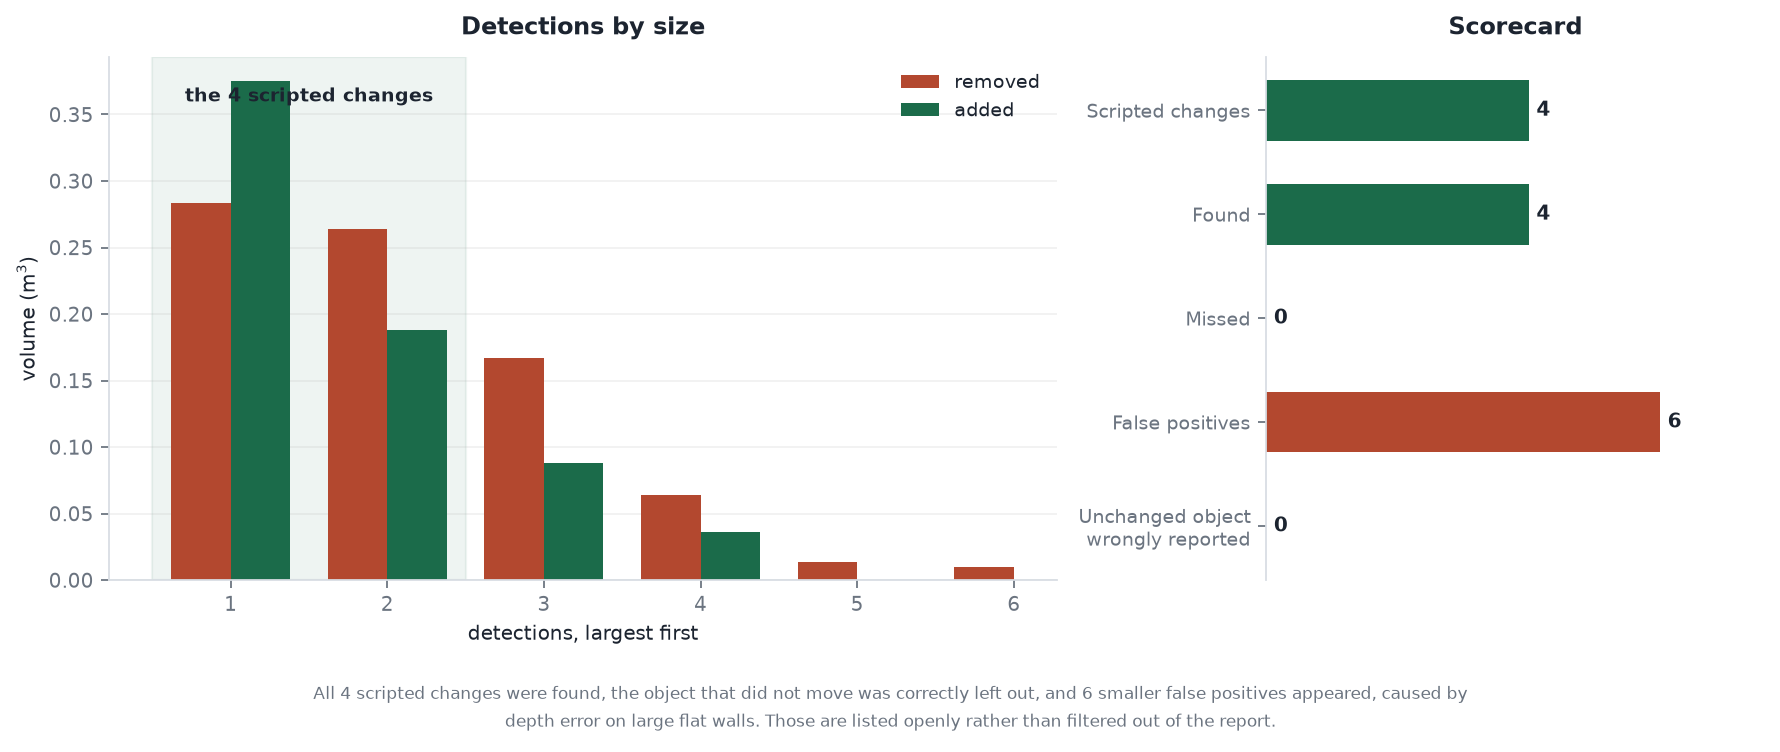

In [8]:
from IPython.display import Image, display
display(Image('../docs/figures/scorecard.png'))

## 6. The part the system refuses to say

Every cluster gets cropped from the frame that saw it best and shown to CLIP,
which scores it against a list of candidate object names.

On this scene CLIP came back with confident sounding answers for every region: a
television, a blanket, the floor. Here is what those answers were actually
worth.

In [9]:
n_vocab = 30
for c in changes:
    m = re.search(r'chance for (\d+) labels', (c.get('evidence') or {}).get('reason', ''))
    if m:
        n_vocab = int(m.group(1))

chance = 1.0 / n_vocab
floor = 2.0 / n_vocab

print('vocabulary size : %d names' % n_vocab)
print('picking at random: %.4f' % chance)
print('confidence floor : %.4f  (twice chance)' % floor)
print()
print('%-9s %8s  %-22s %s' % ('kind', 'score', 'best guess', 'beats chance?'))
print('-' * 68)
for c in changes:
    ev = (c.get('evidence') or {}).get('reason', '')
    g = re.search(r"'([^']+)' scored", ev)
    conf = c.get('label_confidence') or 0.0
    print('%-9s %8.3f  %-22s %s'
          % (c['kind'], conf, g.group(1) if g else 'no close frame',
             'yes' if conf >= floor else 'no'))

vocabulary size : 30 names
picking at random: 0.0333
confidence floor : 0.0667  (twice chance)

kind         score  best guess             beats chance?
--------------------------------------------------------------------
removed      0.035  a television           no
removed      0.035  a television           no
removed      0.034  a television           no
removed      0.034  the floor              no
removed      0.000  no close frame         no
removed      0.035  a blanket              no
added        0.035  a television           no
added        0.035  the floor              no
added        0.035  a television           no
added        0.035  a television           no


**Not one of them beat picking at random.** The model was not choosing, it was
shrugging, and the output was presenting the shrug as a finding.

A floor set at twice chance fixed it. Anything below is reported as an
unidentified object with its size and position, which is what the geometry
actually supports. The report went from six invented findings to ten honest
ones.

That is a worse headline and a much more useful system.

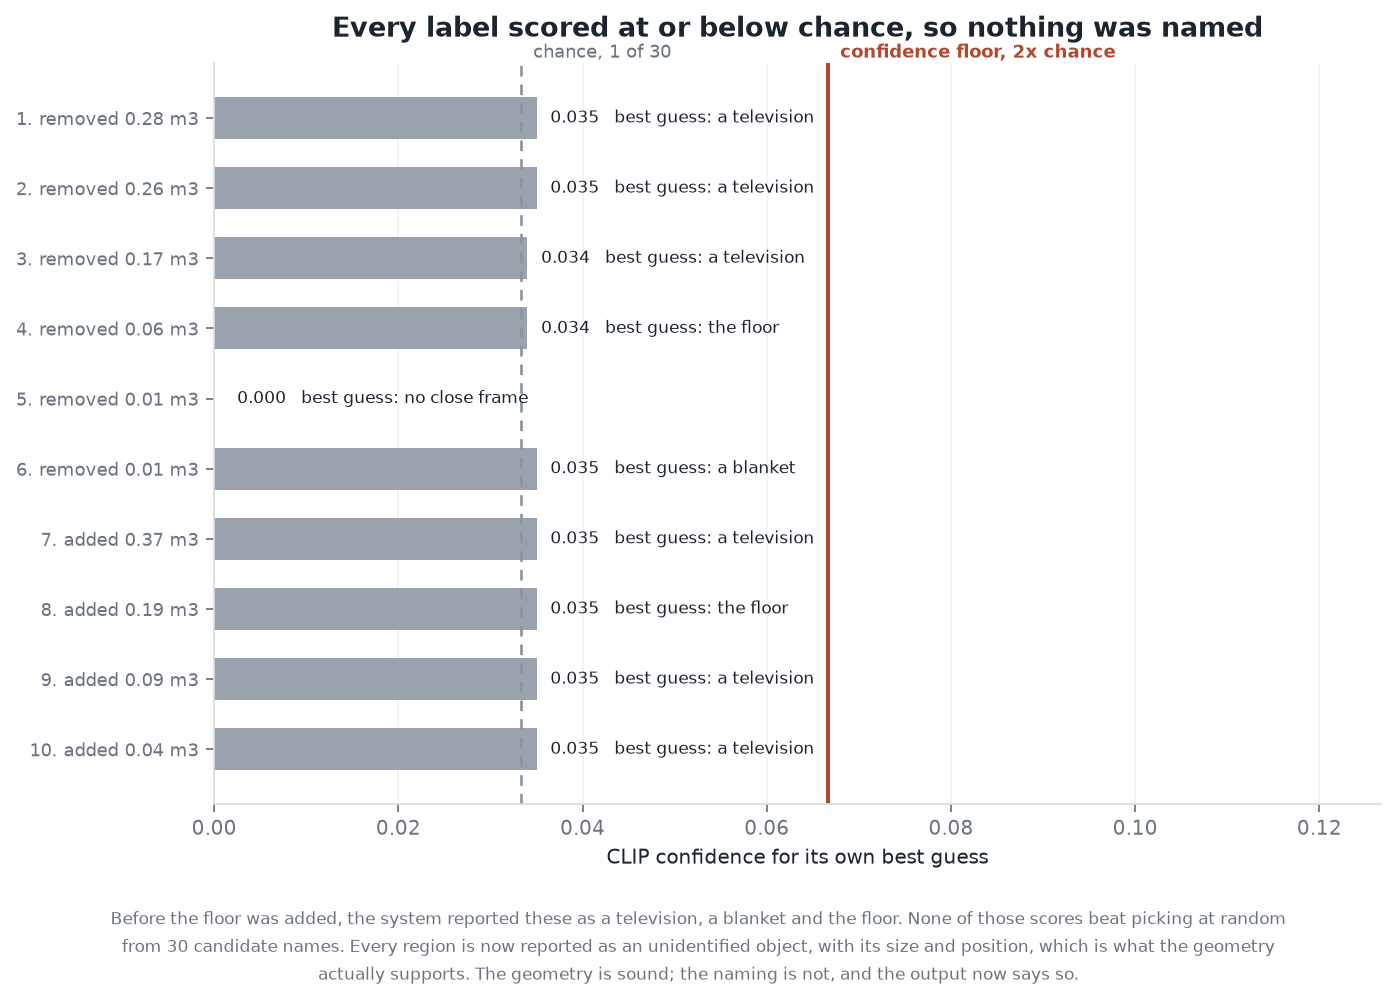

In [10]:
display(Image('../docs/figures/confidence_floor.png'))

## 7. Why the test room looks so strange

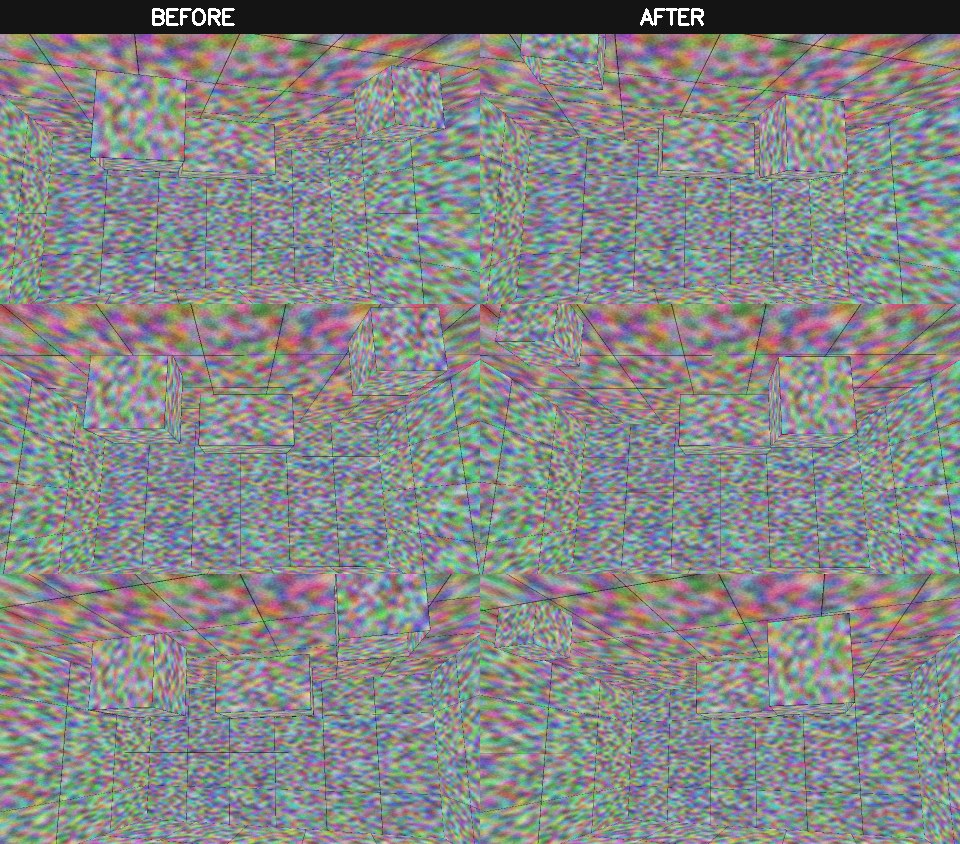

In [11]:
display(Image('../examples/inputs/before_after.jpg'))

It is covered in colourful noise on purpose. Reconstruction works by recognising
the same distinctive patch of texture in several frames, and a smooth evenly
coloured wall gives SIFT nothing to grip on. A photorealistic render would
reconstruct badly for reasons that have nothing to do with the system being
tested, and the test would end up measuring the renderer.

The honest limitation is the other side of that coin: CLIP cannot name a cube
covered in coloured noise. The fake room tests the geometry. Only a real room can
test the naming, and the confidence floor above is what stops the system
pretending otherwise.

## 8. What this does not do

- **No metric scale.** COLMAP's units are arbitrary, so volumes and distances
  are relative rather than in metres. A known size object in shot would fix it.
- **Monocular depth is the weakest link.** Its errors are smooth and plausible,
  which is the worst kind, and they are where the six false positives came from.
- **Conservative by design.** Changes in space only one visit covered are not
  reported. That is the choice made in section 2, not an oversight.
- **A fixed label vocabulary.** CLIP picks the closest entry in `config.yaml`.
  An open vocabulary detector would name things the list never anticipated.
- **It assumes a static scene.** Someone walking through shot registers as
  occupancy.

---

**To reproduce everything from scratch:**

```bash
pip install -r requirements.txt
python tools/make_synthetic_room.py              # renders the two videos
python run.py --a videos/before.mp4 --b videos/after.mp4 \
              --out output/ --config config_synthetic.yaml
python tools/make_readme_figures.py              # charts, from the saved run
```

The pipeline writes results and nothing else. The figure script reads that file
and draws.